# Lab 3 · Radial velocities from seven instruments

As the planet orbits, it pulls its star around their common centre of mass. Spectrographs measure the star's
velocity towards and away from us to metres per second. The size of the swing gives the planet's mass; its
shape gives the eccentricity and orientation of the orbit. Here: 264 velocities of HD 80606 from 2000 to 2021.

In [1]:
import os
import urllib.request
import esl
import esl.plot

DATA = os.environ.get("ESL_DATA", "https://pearsonkyle.github.io/Exoplanet-Science-Lab/examples/")
fetch = lambda path: urllib.request.urlopen(DATA + path).read().decode()

## 1. The velocities

Each instrument (and each era of an instrument) has its own zero point: velocities are relative, measured against
its own reference. `esl.read_rv` makes one dataset per instrument; the fit gives each its own offset (integrated
out analytically, so it costs nothing) and, if you wish, its own extra noise ("jitter").

In [2]:
rv = esl.read_rv(fetch("hd80606/HD80606_RV.csv"))
for d in rv:
    print(f"{d.name:8s} {len(d.time):3d} velocities  {d.time[0]:.1f} to {d.time[-1]:.1f}")

ELODIE    74 velocities  2451508.7 to 2452961.7
HIRES_k   39 velocities  2452007.9 to 2453199.7
HRS       23 velocities  2453346.9 to 2454186.8
HIRES_j   75 velocities  2453398.9 to 2459514.1
SOPHIE    48 velocities  2454871.5 to 2454880.5
APF        5 velocities  2459533.1 to 2459544.0


## 2. Fit the orbit

Free: the period, eccentricity, argument of periastron and the planet's mass, plus a **jitter** per instrument:
extra scatter added in quadrature to the error bars (the star's own surface, or an instrument's systematics).
Without it the fit would treat that scatter as signal (χ² ≈ 1800 for 264 points) and the uncertainties would be
too small. The inclination comes from the transit, so the mass here is the true mass, not M sin i.

In [3]:
cat = esl.lookup("HD 80606 b")
free = [esl.FreeParameter(key=k, prior=esl.Prior.uniform(lo, hi)) for k, lo, hi in [
    ("per", 111.3, 111.6), ("ecc", 0.90, 0.96), ("omega", -70, -50), ("mplanet", 3.0, 5.5)]]
free += [esl.FreeParameter(key=f"jit@rv{i + 1}", prior=esl.Prior.uniform(0, 50)) for i in range(len(rv))]
session = cat.session.model_copy(update=dict(
    name="HD 80606 b · velocities",
    data=esl.Data(radial_velocity=rv),
    fit=esl.FitSettings(use=esl.Use(lc=False, rv=True, timing=False), free=free, sampler=esl.Sampler(nlive=250, seed=4)),
))
fit = session.run()
print(fit.result.table())

converged: 408925 calls, 22.1 s, ln Z = -1027.103 +- 0.352, chi2 = 253.36 for 264 measurements
  per        111.43639 +0.00031 -0.00032
  ecc        0.93157 +0.00046 -0.00045
  omega      -58.86 +0.14 -0.15
  mplanet    4.178 +0.011 -0.010
  jit@rv1    13.6 +2.6 -2.2
  jit@rv2    5.67 +0.99 -0.71
  jit@rv3    16.0 +3.5 -2.4
  jit@rv4    3.75 +0.39 -0.34
  jit@rv5    5.22 +0.97 -0.91
  jit@rv6    5.9 +5.1 -2.6
  derived:
  rpJup      1.0471538
  t14        0.4974 +0.0015 -0.0014
  emid       2458882.200 +0.013 -0.014
  ars        94.452
  b          0.8170 +0.0016 -0.0016
  K          469.5 +1.5 -1.5


## 3. See it

Folded on the period, every instrument lands on one curve once its zero point is removed. The sharp swing is
periastron, when the planet passes 0.03 au from the star (closer than Mercury is to the Sun).

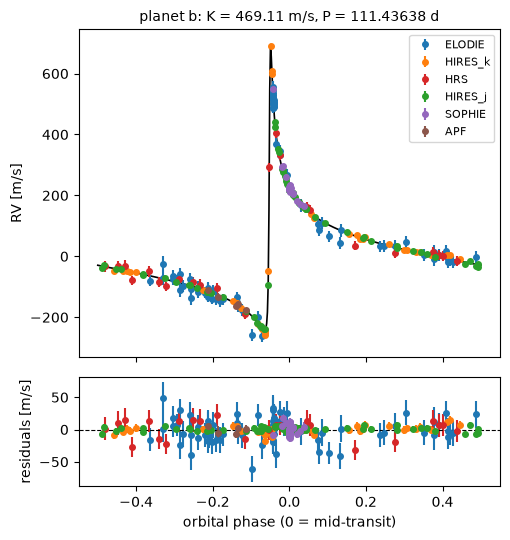

In [4]:
esl.plot.radial_velocity(fit, fold=True);

In [5]:
K = fit.result.derived["K"]
print(f"velocity semi-amplitude K = {K.median:.1f} +{K.plus:.1f} -{K.minus:.1f} m/s (Pearson et al. 2022: 469.2 m/s)")
for z in fit.result.rv_zero_points:
    print(f"  {z.name:8s} zero point {z.gamma:8.1f} m/s, jitter {z.jitter:5.1f} m/s")

velocity semi-amplitude K = 469.5 +1.5 -1.5 m/s (Pearson et al. 2022: 469.2 m/s)
  ELODIE   zero point   3776.6 m/s, jitter  13.8 m/s
  HIRES_k  zero point    -80.6 m/s, jitter   5.4 m/s
  HRS      zero point    -30.9 m/s, jitter  15.3 m/s
  HIRES_j  zero point    -76.7 m/s, jitter   3.7 m/s
  SOPHIE   zero point   3905.4 m/s, jitter   5.1 m/s
  APF      zero point    148.0 m/s, jitter   5.7 m/s


**Next:** [Lab 4](./lab04_joint_fit) puts the transit, the velocities and fifteen years of transit times into one model.